# Publication plot — infinite-RBF kernel first-derivative ODE

Publication-ready comparison for the \(u'=\cos(\omega x)\) kernel solution.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from kapi_onet_publication_style import (
    DOUBLE_COLUMN_WIDTH, BLUE, VERMILLION, BLACK,
    add_major_y_grid, save_figure
)

In [2]:
f=Path("INF_RBF_ODE_COS_RESULTS.npz")
if not f.exists():
    raise FileNotFoundError("Run INF_RBF_ODE_COS_KERNEL.ipynb first.")
S=np.load(f,allow_pickle=False)

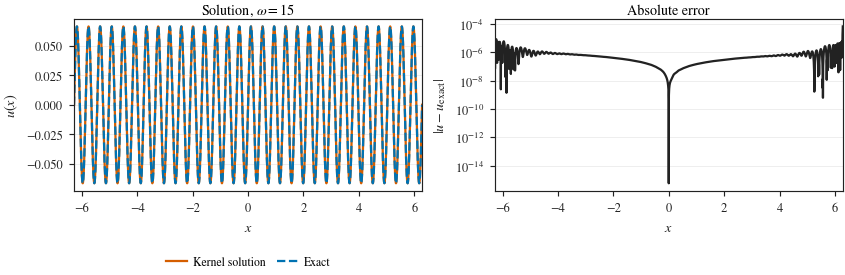

Saved:
  ODE_Cos_Kernel_Comparison.pdf
  ODE_Cos_Kernel_Comparison.png


In [4]:
fig,axes=plt.subplots(
    1,2,
    figsize=(DOUBLE_COLUMN_WIDTH,DOUBLE_COLUMN_WIDTH*0.33),
    constrained_layout=True
)

ax=axes[0]
ax.plot(S["x_test"],S["u_pred"],color=VERMILLION,label="Kernel solution")
ax.plot(S["x_test"],S["u_exact"],"--",color=BLUE,label="Exact")
ax.set_xlim(float(S["xL"]),float(S["xR"]))
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$u(x)$")
ax.set_title(rf"Solution, $\omega={float(S['omega']):g}$")
add_major_y_grid(ax)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.35),
    ncol=2,
    borderaxespad=0.0
)

ax=axes[1]
ax.semilogy(S["x_test"],np.maximum(np.abs(S["error"]),1e-16),color=BLACK)
ax.set_xlim(float(S["xL"]),float(S["xR"]))
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$|u-u_{\rm exact}|$")
ax.set_title("Absolute error")
add_major_y_grid(ax)

saved=save_figure(fig,"ODE_Cos_Kernel_Comparison",formats=("pdf","png"))
plt.show()
print("Saved:",*saved,sep="\n  ")